In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import chebyshev, cityblock, euclidean
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [2]:
df = pd.read_csv("data/Mall_Customers.csv")
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


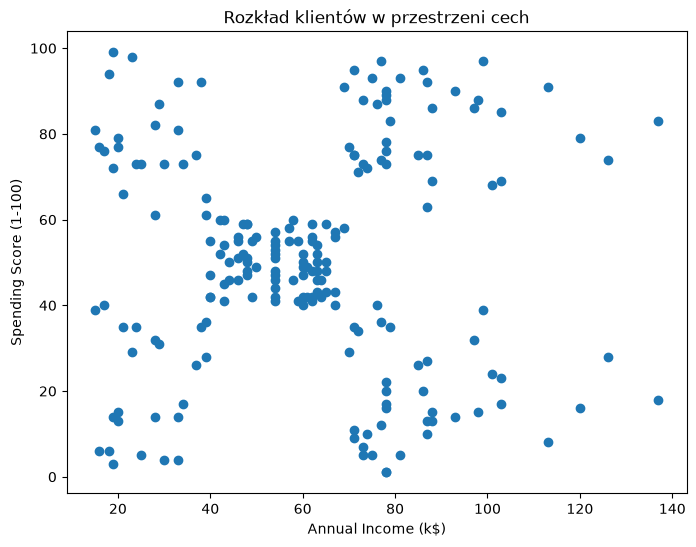

In [3]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
plt.figure(figsize=(8, 6))
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Rozkład klientów w przestrzeni cech")
plt.show()

In [4]:
client_1 = X.iloc[12]
client_2 = X.iloc[123]
euclidean_distance = euclidean(client_1, client_2)
print(f"Odległość euklidesowa: {euclidean_distance:.2f}")
manhattan_distance = cityblock(client_1, client_2)
print(f"Odległość Manhattan: {manhattan_distance:.2f}")
chebyshev_distance = chebyshev(client_1, client_2)
print(f"Odległość Czebyszewa: {chebyshev_distance:.2f}")

Odległość euklidesowa: 90.43
Odległość Manhattan: 125.00
Odległość Czebyszewa: 76.00


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1
 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0
 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1]
[[ 1.00919971 -1.22553537]
 [ 0.99158305  1.23950275]
 [-0.62618966 -0.01439238]]


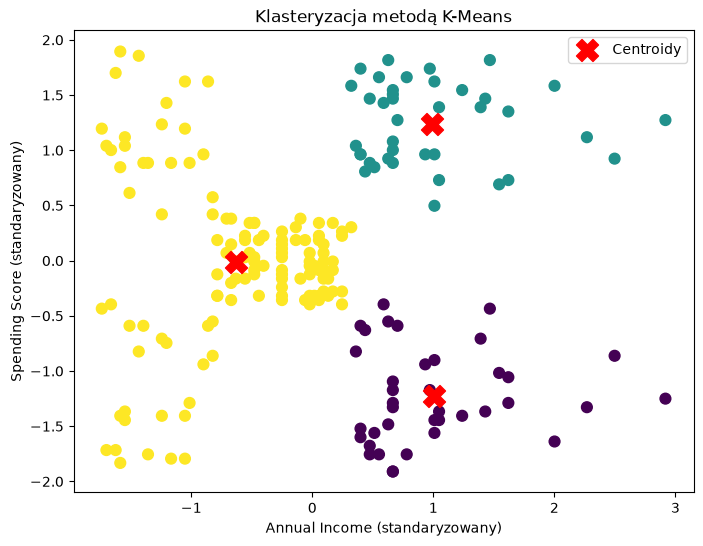

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
print(clusters)
centroids = kmeans.cluster_centers_
print(centroids)
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters, cmap="viridis", s=60)
plt.scatter(
    centroids[:, 0], centroids[:, 1], marker="X", s=250, color="red", label="Centroidy"
)
plt.xlabel("Annual Income (standaryzowany)")
plt.ylabel("Spending Score (standaryzowany)")
plt.title("Klasteryzacja metodą K-Means")
plt.legend()
plt.show()

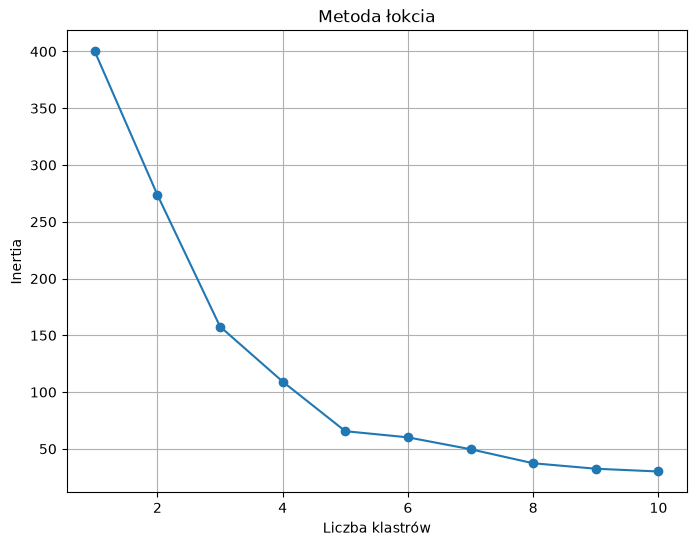

In [7]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.figure(figsize=(8, 6))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Liczba klastrów")
plt.ylabel("Inertia")
plt.title("Metoda łokcia")
plt.grid(True)
plt.show()

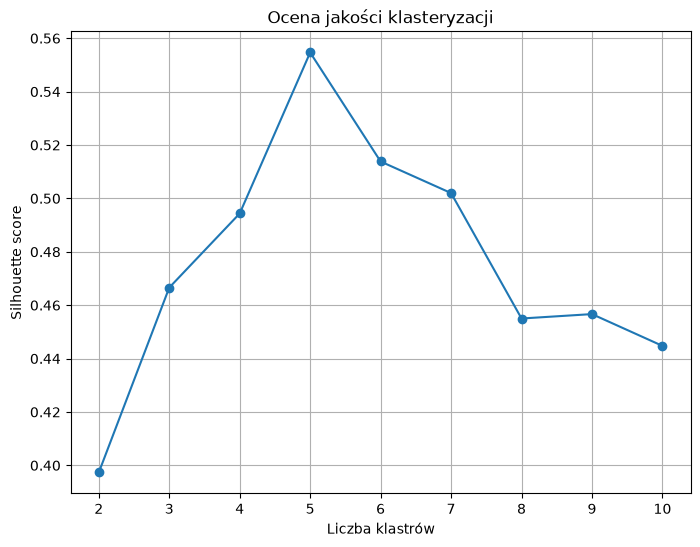

In [8]:
scores = []
k_values = range(2, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    scores.append(score)
plt.figure(figsize=(8, 6))
plt.plot(k_values, scores, marker="o")
plt.xlabel("Liczba klastrów")
plt.ylabel("Silhouette score")
plt.title("Ocena jakości klasteryzacji")
plt.grid(True)
plt.show()

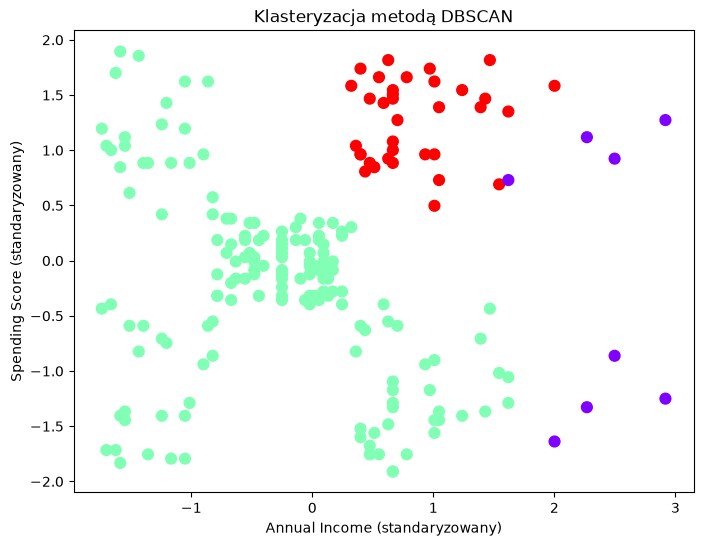

[-1  0  1]


In [9]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
clusters_db = dbscan.fit_predict(X_scaled)
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters_db, cmap="rainbow", s=60)
plt.xlabel("Annual Income (standaryzowany)")
plt.ylabel("Spending Score (standaryzowany)")
plt.title("Klasteryzacja metodą DBSCAN")
plt.show()
print(np.unique(clusters_db))

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Annual Income (k$)      200 non-null    int64
 1   Spending Score (1-100)  200 non-null    int64
 2   Age                     200 non-null    int64
dtypes: int64(3)
memory usage: 4.8 KB
[[-1.73899919 -0.43480148 -1.42456879]
 [-1.73899919  1.19570407 -1.28103541]
 [-1.70082976 -1.71591298 -1.3528021 ]
 [-1.70082976  1.04041783 -1.13750203]
 [-1.66266033 -0.39597992 -0.56336851]]


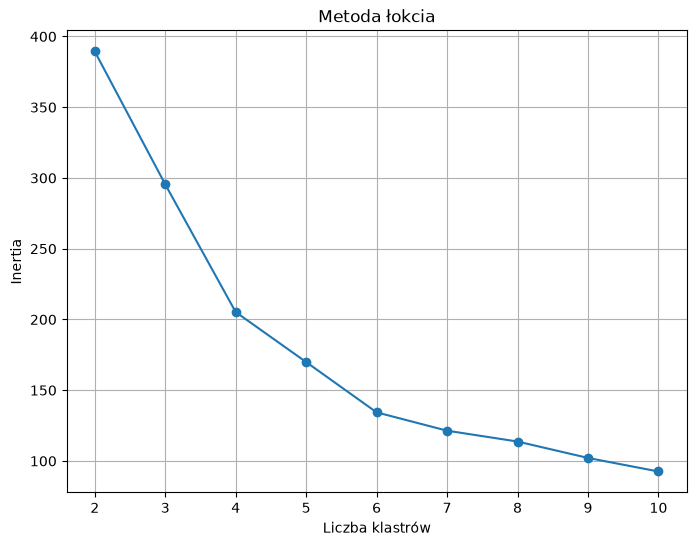

In [10]:
X = df[["Annual Income (k$)", "Spending Score (1-100)", "Age"]]
X.info()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

inertia = []
k_values = range(2, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.figure(figsize=(8, 6))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Liczba klastrów")
plt.ylabel("Inertia")
plt.title("Metoda łokcia")
plt.grid(True)
plt.show()

In [11]:
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
centroids = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=[
        "Annual Income (k$)",
        "Spending Score (1-100)",
        "Age",
    ],
)
centroids.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Annual Income (k$)      4 non-null      float64
 1   Spending Score (1-100)  4 non-null      float64
 2   Age                     4 non-null      float64
dtypes: float64(3)
memory usage: 228.0 bytes


In [12]:
import plotly.express as px
import plotly.graph_objects as go

fig = px.scatter_3d(
    df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    z="Age",
    color=clusters.astype(str),
    opacity=0.8,
    title="Klastry",
)
fig.update_traces(marker_size=5)

fig.add_trace(
    go.Scatter3d(
        x=centroids["Annual Income (k$)"],
        y=centroids["Spending Score (1-100)"],
        z=centroids["Age"],
        mode="markers",
        marker={
            "size": 10,
            "color": "black",
            "symbol": "cross",
            "line": {"color": "white", "width": 2},
        },
        name="Centroidy",
    )
)
fig.show()

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/Mall_Customers.csv")

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

eps=0.20 | klastry: 7 | odstające: 77 | Silhouette: 0.5856
eps=0.25 | klastry: 6 | odstające: 50 | Silhouette: 0.5317
eps=0.30 | klastry: 7 | odstające: 35 | Silhouette: 0.5243
eps=0.35 | klastry: 6 | odstające: 23 | Silhouette: 0.5577
eps=0.40 | klastry: 4 | odstające: 15 | Silhouette: 0.4781
eps=0.45 | klastry: 3 | odstające: 11 | Silhouette: 0.3536
eps=0.50 | klastry: 2 | odstające: 8 | Silhouette: 0.3876
eps=0.55 | klastry: 1 | odstające: 7 | Silhouette: nan
eps=0.60 | klastry: 1 | odstające: 5 | Silhouette: nan
eps=0.65 | klastry: 1 | odstające: 5 | Silhouette: nan
eps=0.70 | klastry: 1 | odstające: 0 | Silhouette: nan


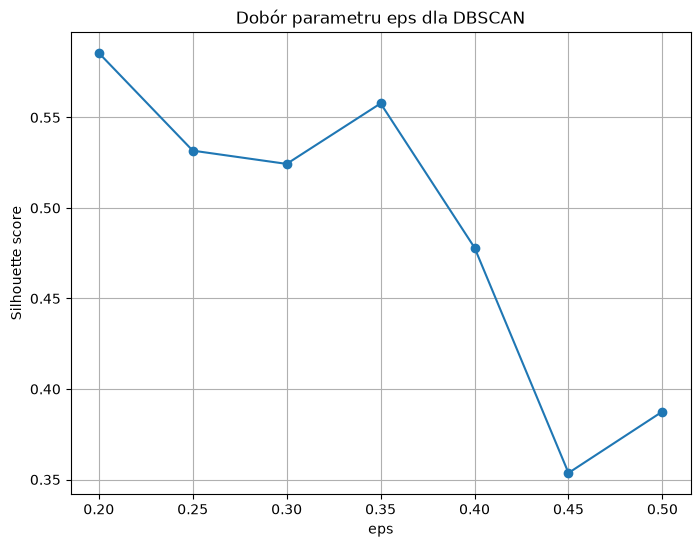


Najlepsza wartość eps: 0.20 (Silhouette = 0.5856)


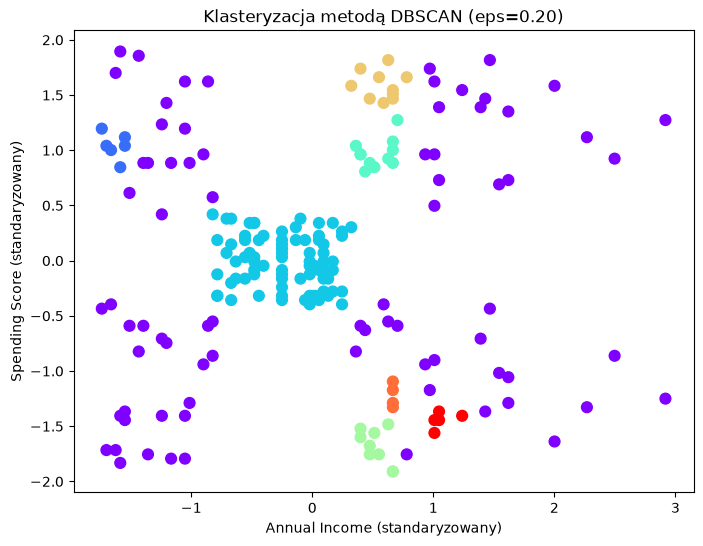

[-1  0  1  2  3  4  5  6]


In [ ]:
eps_values = np.arange(0.2, 0.7 + 0.05, 0.05)  # 0.20, 0.25, ..., 0.70
eps_values = np.round(eps_values, 2)

silhouette_scores = []

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=5)

    labels = dbscan.fit_predict(X_scaled)

    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))

    if n_clusters >= 2:
        score = silhouette_score(X_scaled[mask], labels[mask])
    else:
        score = np.nan

    silhouette_scores.append(score)

# wykres zależności Silhouette od eps
plt.figure(figsize=(8, 6))
plt.plot(eps_values, silhouette_scores, marker="o")
plt.xlabel("eps")
plt.ylabel("Silhouette score")
plt.title("Dobór parametru eps dla DBSCAN")
plt.grid(True)
plt.show()

best_idx = np.nanargmax(silhouette_scores)
best_eps = eps_values[best_idx]
print(
    f"\nNajlepsza wartość eps: {best_eps:.2f} "
    f"(Silhouette = {silhouette_scores[best_idx]:.4f})"
)

dbscan_best = DBSCAN(eps=best_eps, min_samples=5)

clusters_best = dbscan_best.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters_best, cmap="rainbow", s=60)

plt.xlabel("Annual Income (standaryzowany)")
plt.ylabel("Spending Score (standaryzowany)")
plt.title(f"Klasteryzacja metodą DBSCAN (eps={best_eps:.2f})")

plt.show()

print(np.unique(clusters_best))

Metryka: euclidean  | klastry: 2 | odstające: 8 | Silhouette: 0.3876


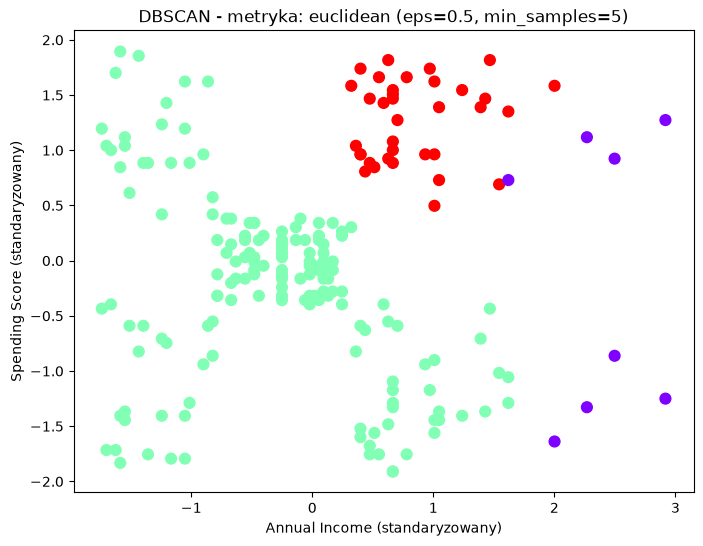

Metryka: manhattan  | klastry: 4 | odstające: 15 | Silhouette: 0.4735


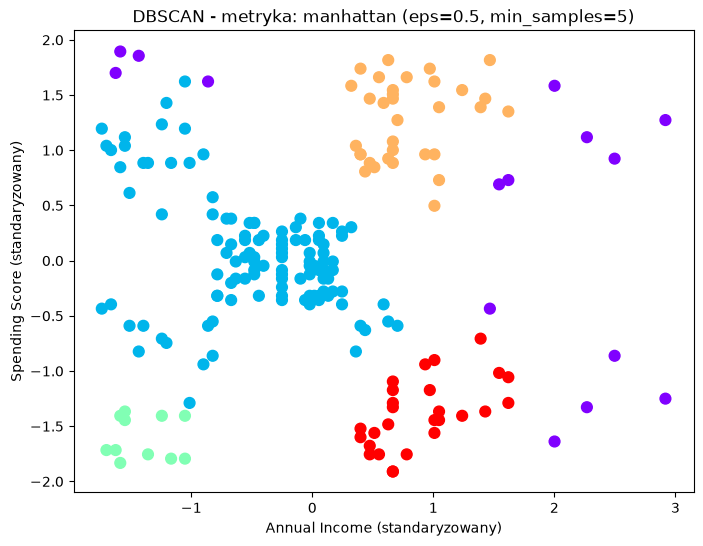

Metryka: chebyshev  | klastry: 1 | odstające: 7 | Silhouette: nan


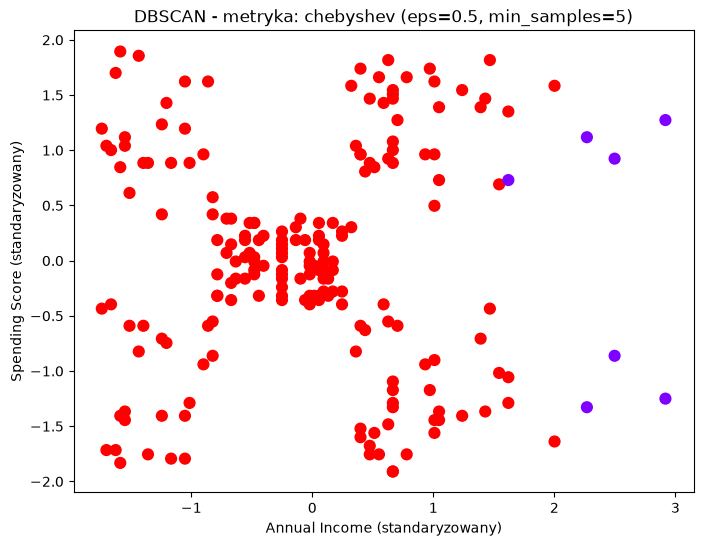

In [16]:
metrics = ["euclidean", "manhattan", "chebyshev"]

for metric in metrics:
    dbscan = DBSCAN(eps=0.5, min_samples=5, metric=metric)

    labels = dbscan.fit_predict(X_scaled)

    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))
    n_noise = np.sum(~mask)

    if n_clusters >= 2:
        score = silhouette_score(X_scaled[mask], labels[mask], metric=metric)
    else:
        score = np.nan

    print(
        f"Metryka: {metric:10s} | klastry: {n_clusters} | "
        f"odstające: {n_noise} | Silhouette: {score:.4f}"
    )

    plt.figure(figsize=(8, 6))
    plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="rainbow", s=60)

    plt.xlabel("Annual Income (standaryzowany)")
    plt.ylabel("Spending Score (standaryzowany)")
    plt.title(f"DBSCAN - metryka: {metric} (eps=0.5, min_samples=5)")

    plt.show()